Car Sales Price Predction - ANN
---
Problem Statement - The objective of this project is to build an ANN model that predicts the selling price of a car based on its features.

Objective :-
---
a.Predict car selling prices using ANN.

b.Learn complex relationships between vehicle features and price.

c.Improve prediction accuracy through preprocessing and feature engineering.

d.Evaluate model performance using regression metrics.

Overview :-
----
Dataset - Car price prediction

Source - Kaggle

Problem Type - Regression(Continuous)

Algorithm - ANN

Target Variable - Price

Features :-
-------
Customer Name, Customer Email, Country, Gender, Age, Annual Salary, Credit Card Debt, Net Worth and 
Car Purchase Amount.

In [340]:
#Step1-Imporitng basic Libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

In [285]:
#Step2-Loading the dataset
cp = pd.read_csv("car_purchasing.csv", encoding="latin1")
cp.head()

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount
0,Martina Avila,cubilia.Curae.Phasellus@quisaccumsanconvallis.edu,Bulgaria,0,41.851720,62812.09301,11609.380910,238961.2505,35321.45877
1,Harlan Barnes,eu.dolor@diam.co.uk,Belize,0,40.870623,66646.89292,9572.957136,530973.9078,45115.52566
2,Naomi Rodriquez,vulputate.mauris.sagittis@ametconsectetueradip...,Algeria,1,43.152897,53798.55112,11160.355060,638467.1773,42925.70921
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313
4,Cedric Leach,felis.ullamcorper.viverra@egetmollislectus.net,Brazil,1,57.313749,59729.15130,5358.712177,560304.0671,55915.46248


In [286]:
#Step3-Explore the dataset
cp.shape 
#500 rows and 9 columns.

(500, 9)

In [287]:
cp.columns

Index(['customer name', 'customer e-mail', 'country', 'gender', 'age',
       'annual Salary', 'credit card debt', 'net worth',
       'car purchase amount'],
      dtype='object')

In [288]:
cp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer name        500 non-null    object 
 1   customer e-mail      500 non-null    object 
 2   country              500 non-null    object 
 3   gender               500 non-null    int64  
 4   age                  500 non-null    float64
 5   annual Salary        500 non-null    float64
 6   credit card debt     500 non-null    float64
 7   net worth            500 non-null    float64
 8   car purchase amount  500 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 35.3+ KB


In [289]:
cp.describe() 
#Statistical summary of numerical features.

,gender,age,annual Salary,credit card debt,net worth,car purchase amount
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,0.506000,46.241674,62127.239608,9607.645049,431475.713625,44209.799218
std,0.500465,7.978862,11703.378228,3489.187973,173536.756340,10773.178744
min,0.000000,20.000000,20000.000000,100.000000,20000.000000,9000.000000
25%,0.000000,40.949969,54391.977195,7397.515792,299824.195900,37629.896040
50%,1.000000,46.049901,62915.497035,9655.035568,426750.120650,43997.783390
75%,1.000000,51.612263,70117.862005,11798.867487,557324.478725,51254.709517
max,1.000000,70.000000,100000.000000,20000.000000,1000000.000000,80000.000000


In [290]:
#Missing values per column
cp.isnull().sum()

customer name          0
customer e-mail        0
country                0
gender                 0
age                    0
annual Salary          0
credit card debt       0
net worth              0
car purchase amount    0
dtype: int64

In [291]:
print(cp.duplicated().sum())

0


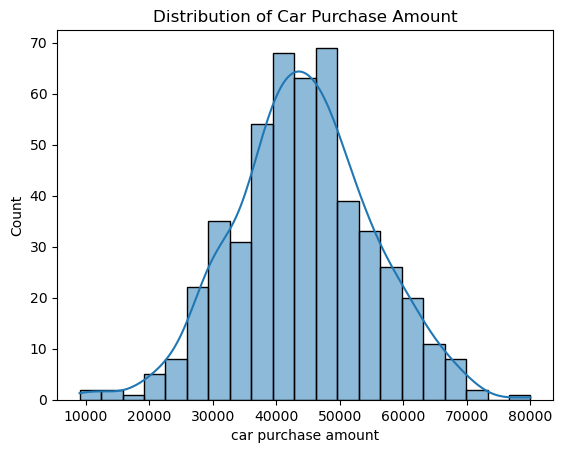

In [292]:
#Step4-Visualize
sns.histplot(cp['car purchase amount'], kde=True)
plt.title("Distribution of Car Purchase Amount")
plt.show()

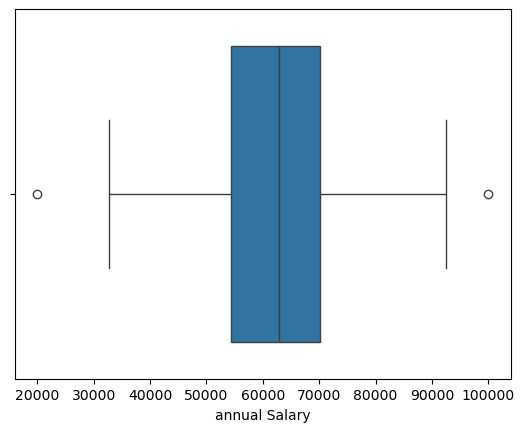

In [293]:
sns.boxplot(x=cp["annual Salary"])
plt.show()

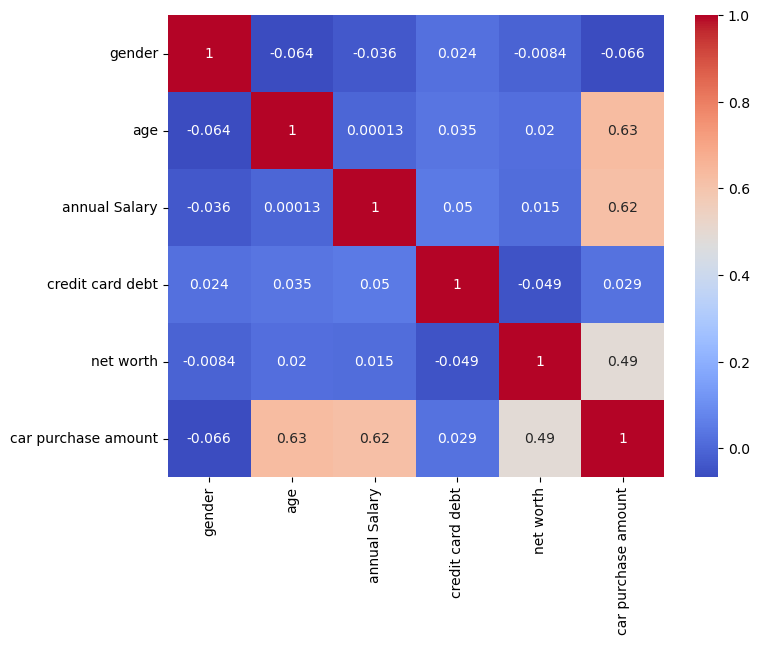

In [294]:
plt.figure(figsize=(8,6))
sns.heatmap(cp.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")
plt.show()
#Red shows positive correlation and Blur shows negative correlation.

In [295]:
# sns.pairplot(cp)
# plt.show()

In [296]:
# sns.scatterplot(
#     x="annual Salary",
#     y="car purchase amount",
#     data=cp
# )
# plt.show()

In [297]:
#Feature Engineering
cp.tail()

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount
495,Walter,ligula@Cumsociis.ca,Nepal,0,41.462515,71942.40291,6995.902524,541670.1016,48901.44342
496,Vanna,Cum.sociis.natoque@Sedmolestie.edu,Zimbabwe,1,37.642000,56039.49793,12301.456790,360419.0988,31491.41457
497,Pearl,penatibus.et@massanonante.com,Philippines,1,53.943497,68888.77805,10611.606860,764531.3203,64147.28888
498,Nell,Quisque.varius@arcuVivamussit.net,Botswana,1,59.160509,49811.99062,14013.034510,337826.6382,45442.15353
499,Marla,Camaron.marla@hotmail.com,marlal,1,46.731152,61370.67766,9391.341628,462946.4924,45107.22566


In [298]:
cp.columns

Index(['customer name', 'customer e-mail', 'country', 'gender', 'age',
       'annual Salary', 'credit card debt', 'net worth',
       'car purchase amount'],
      dtype='object')

In [299]:
cp.drop(['customer name' , 'customer e-mail'],axis =1,inplace = True)

In [300]:
a= cp["country"].nunique()
print(f"The Number of Unique values in Country is : {a}" )

The Number of Unique values in Country is : 211


In [301]:
b=cp['gender'].nunique()
print(f"Unique Vlaues in Gender is : {b}")

Unique Vlaues in Gender is : 2


In [302]:
cp.shape

(500, 7)

In [303]:
#Seprate the dataset into dependent and independent features.
c = cp.iloc[: , :6]
c

,country,gender,age,annual Salary,credit card debt,net worth
0,Bulgaria,0,41.851720,62812.09301,11609.380910,238961.2505
1,Belize,0,40.870623,66646.89292,9572.957136,530973.9078
2,Algeria,1,43.152897,53798.55112,11160.355060,638467.1773
3,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524
4,Brazil,1,57.313749,59729.15130,5358.712177,560304.0671
...,...,...,...,...,...,...
495,Nepal,0,41.462515,71942.40291,6995.902524,541670.1016
496,Zimbabwe,1,37.642000,56039.49793,12301.456790,360419.0988
497,Philippines,1,53.943497,68888.77805,10611.606860,764531.3203
498,Botswana,1,59.160509,49811.99062,14013.034510,337826.6382


In [304]:
d = cp.iloc[ : , -1:]
d

,car purchase amount
0,35321.45877
1,45115.52566
2,42925.70921
3,67422.36313
4,55915.46248
...,...
495,48901.44342
496,31491.41457
497,64147.28888
498,45442.15353


In [305]:
c_rc = c.shape
print(f"Shape of Independent feature :{c_rc}")
d_rc = d.shape
print(f"Shape of Dependent Feature : {d_rc}")

Shape of Independent feature :(500, 6)
Shape of Dependent Feature : (500, 1)


In [306]:
#encoding the column - Country
# Country = pd.get_dummies(c['country'],dtype = int)
# Country.tail()
country_counts = c["country"].value_counts()

common_countries = country_counts[country_counts >= 5].index

c["country"] = c["country"].where(
    c["country"].isin(common_countries),
    "Other"
)

In [307]:
c = pd.get_dummies(
    c,
    columns=["country"],
    drop_first=True,
    dtype=int
)

In [308]:
c.head()

,gender,age,annual Salary,credit card debt,net worth,country_Armenia,country_Bhutan,country_Bolivia,country_Equatorial Guinea,country_Greenland,...,country_Guinea,country_Iraq,country_Israel,country_Kyrgyzstan,country_Laos,country_Liechtenstein,country_Mauritania,country_Other,country_Saint Barthélemy,country_Samoa
0,0,41.851720,62812.09301,11609.380910,238961.2505,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,0,40.870623,66646.89292,9572.957136,530973.9078,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,1,43.152897,53798.55112,11160.355060,638467.1773,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,58.271369,79370.03798,14426.164850,548599.0524,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,1,57.313749,59729.15130,5358.712177,560304.0671,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [309]:
c.shape

(500, 21)

In [310]:
c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   gender                     500 non-null    int64  
 1   age                        500 non-null    float64
 2   annual Salary              500 non-null    float64
 3   credit card debt           500 non-null    float64
 4   net worth                  500 non-null    float64
 5   country_Armenia            500 non-null    int32  
 6   country_Bhutan             500 non-null    int32  
 7   country_Bolivia            500 non-null    int32  
 8   country_Equatorial Guinea  500 non-null    int32  
 9   country_Greenland          500 non-null    int32  
 10  country_Grenada            500 non-null    int32  
 11  country_Guinea             500 non-null    int32  
 12  country_Iraq               500 non-null    int32  
 13  country_Israel             500 non-null    int32  

In [311]:
total =len([col for col in c.columns if col.startswith("country_")])
print(f"Number of Countries Columns : {total}")

Number of Countries Columns : 16


In [312]:
#Splitting dataset into training and test
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [313]:
sc = StandardScaler()

In [314]:
x_train,x_test,y_train,y_test = train_test_split(c,d, test_size = 0.2, random_state = 42)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(400, 21)
(100, 21)
(400, 1)
(100, 1)


In [315]:
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [316]:
print(x_train[:5])

[[-1.         -1.22996274  0.70264523  0.06782569  1.14322143 -0.08692914
  -0.10050378 -0.11250879 -0.08692914 -0.08692914 -0.11250879 -0.10050378
  -0.10050378 -0.10050378 -0.11250879 -0.10050378 -0.11250879 -0.12340351
   0.45256964 -0.11250879 -0.11250879]
 [ 1.         -0.76993543 -0.49583563 -0.85967664 -1.16188481 -0.08692914
  -0.10050378 -0.11250879 -0.08692914 -0.08692914 -0.11250879 -0.10050378
  -0.10050378 -0.10050378 -0.11250879 -0.10050378 -0.11250879 -0.12340351
   0.45256964 -0.11250879 -0.11250879]
 [-1.          1.58484034 -0.55624875  1.05701072  0.76354398 -0.08692914
  -0.10050378 -0.11250879 -0.08692914 -0.08692914 -0.11250879 -0.10050378
   9.94987437 -0.10050378 -0.11250879 -0.10050378 -0.11250879 -0.12340351
  -2.2096047  -0.11250879 -0.11250879]
 [-1.          1.76378125 -0.26438912  0.91818965  1.08462189 -0.08692914
  -0.10050378 -0.11250879 -0.08692914 -0.08692914 -0.11250879 -0.10050378
  -0.10050378 -0.10050378 -0.11250879 -0.10050378 -0.11250879 -0.1234

In [317]:
#Building the ANN model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import ReLU
from tensorflow.keras.layers import Dropout 

In [318]:
model = Sequential()

In [319]:
#Input Layer
model.add(Dense( units= 12 ,activation='relu',input_shape=(x_train.shape[1],),kernel_initializer="he_uniform"))

c:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [320]:
#Hidden layers
model.add(Dense(units = 8 , activation ="relu")) #1st
model.add(Dropout(0.3))
model.add(Dense(units = 7 , activation ="relu")) #2nd
model.add(Dropout(0.4))
model.add(Dense(units = 6 , activation="relu")) #3rd
model.add(Dropout(0.2))

In [321]:
#Adding output layer
model.add(Dense(units = 1 , activation ="relu"))

In [322]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 12)             │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 7)              │            63 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 6)              │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 486 (1.90 KB)

 Trainable params: 486 (1.90 KB)

 Non-trainable params: 0 (0.00 B)

In [323]:
model.compile(optimizer='Adam', loss='mse', metrics=['mae'])

In [324]:
#Early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.001,
    patience= 20,
    verbose = 1 ,
    mode = "auto",
    baseline = None,
    restore_best_weights= False ,
)

In [325]:
MODEL = model.fit(x_train,y_train,validation_split=0.2 , batch_size= 32, epochs = 100  , callbacks = early_stopping)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 2076123904.0000 - mae: 44200.2695 - val_loss: 1938663424.0000 - val_mae: 42925.1992
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2076099328.0000 - mae: 44200.0000 - val_loss: 1938642944.0000 - val_mae: 42924.9570
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2076073216.0000 - mae: 44199.7109 - val_loss: 1938617600.0000 - val_mae: 42924.6602
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2076043648.0000 - mae: 44199.3867 - val_loss: 1938584832.0000 - val_mae: 42924.2852
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2076005632.0000 - mae: 44198.9375 - val_loss: 1938543360.0000 - val_mae: 42923.8047
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2075959040.0000 - mae: 44198.4453 - val_loss: 1938488320.0000 - val_mae: 42923.1680
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2075878656.0000 - mae: 44197.5430 - val_loss: 1938418944.0000 - val_mae: 42922.367

In [326]:
MODEL.history.keys()

dict_keys(['loss', 'mae', 'val_loss', 'val_mae'])

In [327]:
y_pred = model.predict(x_test)
y_pred = (y_pred > 0.5)

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/stepWARNING:tensorflow:6 out of the last 12 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x00000287BFFFB100> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [328]:
model.get_weights()

[array([[ 0.19726816, -0.06374421, -1.2190211 ,  0.6159316 , -0.28989598,
         -1.2092009 ,  0.9809648 ,  0.80114675, -0.536186  , -0.8393914 ,
         -1.2920772 ,  1.6309516 ],
        [ 1.2436569 ,  1.0028436 ,  0.6231407 ,  0.35579956,  0.26452106,
          0.93468666, -0.5730043 ,  1.2210746 ,  0.31291714,  0.51462924,
          0.67848897,  1.0807043 ],
        [ 1.3767804 , -0.1452103 ,  0.02048715,  0.8904027 ,  0.868017  ,
          0.52012116,  1.3307284 , -0.44115713,  1.2805585 , -0.40292108,
         -0.43477547,  1.2744918 ],
        [-0.8623329 ,  0.9642098 ,  0.8453887 , -0.5783859 , -0.3078753 ,
         -0.07143124, -1.0025675 ,  0.98560756, -1.1671891 ,  0.8848321 ,
         -0.9614661 ,  0.7285419 ],
        [-0.13532403,  1.3880624 ,  0.2954164 ,  0.59300953,  0.234227  ,
          1.1175191 , -0.86032456,  0.91887814,  0.6474002 ,  0.80064   ,
          1.0212202 , -0.24834386],
        [-1.5134257 , -1.9023019 ,  0.507297  , -1.4791253 ,  0.26089603,
      

In [329]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE : 45263.71311720001
MSE : 2156776884.6707563
RMSE: 46441.11200941205
R² Score: -18.97512061670901


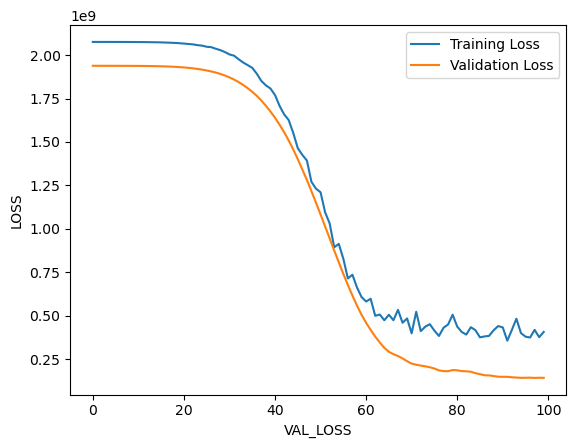

In [341]:
plt.plot(MODEL.history['loss'], label='Training Loss')
plt.plot(MODEL.history['val_loss'], label='Validation Loss')
plt.xlabel("VAL_LOSS")
plt.ylabel("LOSS")
plt.legend()
plt.show()

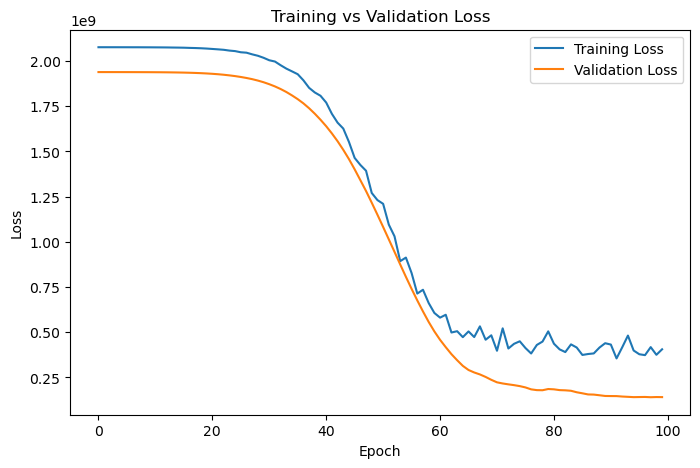

In [332]:
plt.figure(figsize=(8,5))

plt.plot(MODEL.history['loss'], label='Training Loss')
plt.plot(MODEL.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.show()

In [333]:
y_pred = model.predict(x_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


In [334]:
print(y_pred[:10])

[[36771.22 ]
 [35558.098]
 [52857.62 ]
 [26244.506]
 [53169.695]
 [55740.633]
 [43430.586]
 [47462.38 ]
 [43234.53 ]
 [38413.707]]


In [335]:
import pandas as pd

results = pd.DataFrame({
    "Actual": y_test.values.flatten(),
    "Predicted": y_pred.flatten()
})

print(results.head(10))

        Actual     Predicted
0  46082.80993  36771.218750
1  45058.89690  35558.097656
2  63079.84329  52857.621094
3  31837.22537  26244.505859
4  60461.24268  53169.695312
5  63140.05082  55740.632812
6  52477.83479  43430.585938
7  54755.42038  47462.378906
8  52707.96816  43234.531250
9  47869.82593  38413.707031


In [336]:
print(y_pred.shape)

(100, 1)


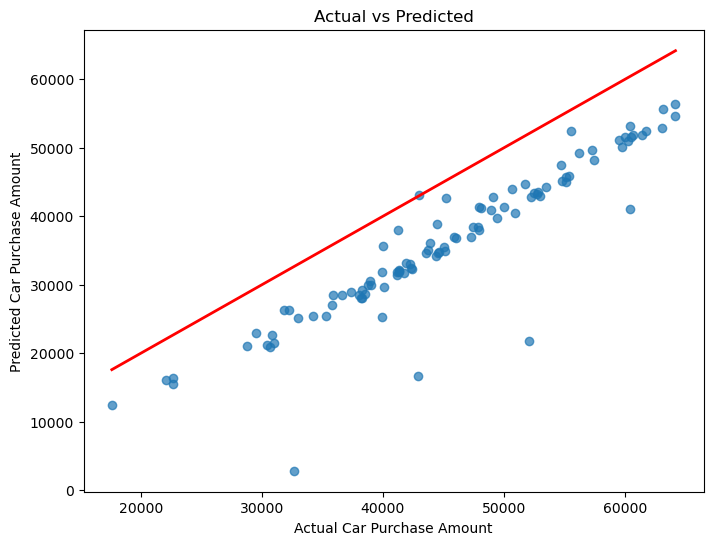

In [337]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.xlabel("Actual Car Purchase Amount")
plt.ylabel("Predicted Car Purchase Amount")
plt.title("Actual vs Predicted")

plt.show()